
###  Dimensionality reduction


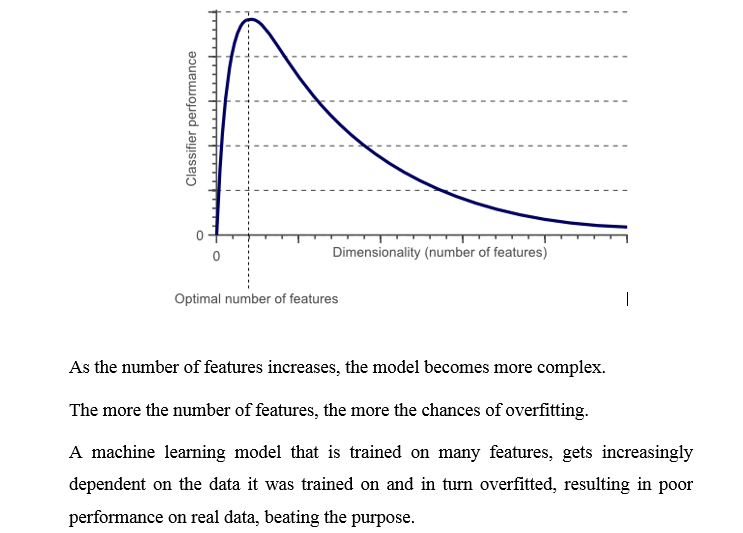

### PCA

In [ ]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

In [ ]:

url = "data/iris.csv"

df = pd.read_csv(url, names=['sepal length','sepal width','petal length','petal width','target'])
df

In [ ]:

features = ['sepal length', 'sepal width', 'petal length', 'petal width']

x = df.loc[:, features].values
x

In [ ]:
y = df.loc[:,['target']].values

print(y)

In [ ]:

X = StandardScaler().fit_transform(x)

print(X)

In [ ]:

from sklearn.decomposition import PCA

pca = PCA(n_components=3)

principalComponents = pca.fit_transform(x)

print(principalComponents)


In [ ]:

principalDf = pd.DataFrame(data = principalComponents, columns = ['pc1','pc2','pc3'])

print(principalDf)

In [ ]:

finalDf = pd.concat([principalDf, df[['target']]], axis = 1)

print(finalDf)

In [ ]:

pca.explained_variance_ratio_

In [ ]:

exp_var_cum=np.cumsum(pca.explained_variance_ratio_)

print(exp_var_cum)

In [ ]:

plt.step(range(exp_var_cum.size), exp_var_cum)

In [ ]:

pd.DataFrame({'Components':['C1', 'c2','C3'],'Variance':pca.explained_variance_ratio_}).plot.bar(x='Components',y='Variance',rot=0)


<b>explained_variance_ratio</b> is used to determine the number of principal components that sufficiently provides the information contained in the original feature.



PCA doesn’t work well on high dimensional sparse matrix due to computational constraints resulting in a memory error issue. 

In such cases, TruncatedSVD can be used.

### SVD

In [ ]:

x = df.loc[:, features].values
x

In [ ]:

y = df.loc[:,['target']].values
y

In [ ]:

x = StandardScaler().fit_transform(x)
x

In [ ]:

from sklearn.decomposition import TruncatedSVD 

svd = TruncatedSVD(n_components=3) 

svd.fit_transform(x)

pd.DataFrame({'Components':['C1','C2', 'C3'],'Variance':svd.explained_variance_ratio_}).plot.bar(x='Components',y='Variance',rot=0)


In [ ]:

svd.explained_variance_ratio_

In [ ]:

exp_var_cum=np.cumsum(svd.explained_variance_ratio_)

print(exp_var_cum)

### LDA

In [ ]:

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

In [ ]:

features = ['sepal length', 'sepal width', 'petal length', 'petal width']

X = df[features].values
y = df['target'].values


In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [ ]:

lda = LinearDiscriminantAnalysis(n_components=1)

X_lda = lda.fit_transform(X_scaled, y)

print("Original shape:", X.shape)

print("Reduced shape:", X_lda.shape)

print("Explained variance ratio:", lda.explained_variance_ratio_)
